# Hierarchical Clustering: Customer Segmentation (Online Retail II)

Complete end-to-end notebook:

1. Setup and configuration
2. Load data
3. Data understanding and cleaning
4. Exploratory data analysis
5. RFM feature engineering
6. Outliers, log transform and scaling
7. **Hierarchical clustering from scratch** (to understand the algorithm)
8. Hierarchical clustering with SciPy (fast, production version)
9. Comparing linkage methods (cophenetic correlation)
10. Dendrogram
11. Choosing the number of clusters (Silhouette, Davies-Bouldin, Calinski-Harabasz) and a side-by-side K comparison with stability
12. Final model
13. Cluster profiling and segment naming
14. Visualization (PCA, 3D, boxplots, heatmap, clustermap)
15. Validation (stability and comparison with K-Means)
16. Business recommendations and export (all graphs go to `results/graphs/`, all tables to `results/tables_csv/`)

**Dataset:** UCI / Kaggle *Online Retail II* (about 1.07M transactions, Dec 2009 to Dec 2011).

## 1. Setup and configuration

In [47]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [48]:
# ---------------- CONFIGURATION ----------------
DATA_PATH = "Data/online_retail_II.csv"   # change to your file path (.csv or .xlsx)

# ---- Output folders: everything this notebook produces is saved here automatically ----
import os
RESULTS_DIR = "results"
GRAPHS_DIR = os.path.join(RESULTS_DIR, "graphs")        # all figures (PNG)
CSV_DIR = os.path.join(RESULTS_DIR, "tables_csv")       # all tables (CSV)
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(CSV_DIR, exist_ok=True)
OUTPUT_PATH = os.path.join(CSV_DIR, "00_customer_segments_final.csv")

# Number of clusters. Default 3: silhouette picks K=2 on this data, but K=2 only splits
# "valuable vs low value" (a continuum cut in two). K=3 is the next best supported by the metrics,
# and K=6 is a second natural level (see section 11b). Set to None to use the best silhouette K.
FORCE_K = 3
K_RANGE = range(2, 11)


def save_fig(name, fig=None):
    # save the current (or given) figure to results/graphs/<name>.png
    fig = fig if fig is not None else plt.gcf()
    path = os.path.join(GRAPHS_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[saved graph] {path}")


def save_csv(table, name, index=True):
    # save a DataFrame to results/tables_csv/<name>.csv
    path = os.path.join(CSV_DIR, f"{name}.csv")
    table.to_csv(path, index=index)
    print(f"[saved table] {path}")

## 2. Load data

The notebook supports both the Kaggle CSV and the UCI Excel file (which has two sheets that are combined).
Column names are standardised, since different versions use different names.

In [49]:
def load_data(path):
    if path.lower().endswith((".xlsx", ".xls")):
        sheets = pd.read_excel(path, sheet_name=None)      # reads all sheets
        raw = pd.concat(sheets.values(), ignore_index=True)
    else:
        try:
            raw = pd.read_csv(path)
        except UnicodeDecodeError:
            raw = pd.read_csv(path, encoding="ISO-8859-1")
    # standardise column names across dataset versions
    raw = raw.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price",
                              "CustomerID": "Customer ID"})
    return raw

raw = load_data(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Data understanding and cleaning

In [50]:
raw.info()
print()
print("Missing values per column:")
print(raw.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB

Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [51]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,1067371,53628,537434,1350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,172.705794,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,1067371,47635,2010-12-06 16:57:00,1350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,123.553059,-53594.36,1.25,2.1,4.15,38970.0
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,1697.46445,12346.0,13975.0,15255.0,16797.0,18287.0
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Cleaning rules

| Problem | Action |
|---|---|
| Missing `Customer ID` | Remove (cannot segment an unknown customer) |
| Invoice starting with `C` | Remove (cancellations) |
| `Quantity <= 0` or `Price <= 0` | Remove (returns, bad debt, adjustments) |
| Non-product stock codes (POST, DOT, M, BANK CHARGES ...) | Remove (postage and fees, not customer purchases) |
| Duplicates | Remove |

In [52]:
df = raw.copy()
n0 = len(df)
log = []

def step(name, d):
    log.append((name, len(d), n0 - len(d)))
    return d

df = step("raw", df)
df = df.dropna(subset=["Customer ID"]);                               df = step("drop missing Customer ID", df)
df = df[~df["Invoice"].astype(str).str.upper().str.startswith("C")];  df = step("drop cancellations (C...)", df)
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)];                    df = step("drop Quantity<=0 or Price<=0", df)

# non-product codes: postage, discounts, manual entries, fees ...
non_product = r"^(POST|D|DOT|M|BANK CHARGES|AMAZONFEE|CRUK|S|B|ADJUST|TEST\d*|PADS)$"
df = df[~df["StockCode"].astype(str).str.upper().str.match(non_product)];  df = step("drop non-product codes", df)

df = df.drop_duplicates();                                            df = step("drop duplicates", df)

df["Customer ID"] = df["Customer ID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["Price"]

cleaning_log = pd.DataFrame(log, columns=["step", "rows_left", "total_removed"])
save_csv(cleaning_log, "01_cleaning_log", index=False)
cleaning_log

[saved table] results\tables_csv\01_cleaning_log.csv


,step,rows_left,total_removed
0,raw,1067371,0
1,drop missing Customer ID,824364,243007
2,drop cancellations (C...),805620,261751
3,drop Quantity<=0 or Price<=0,805549,261822
4,drop non-product codes,802890,264481
5,drop duplicates,776830,290541


In [53]:
print("Clean transactions:", df.shape)
print("Unique customers  :", df["Customer ID"].nunique())
print("Date range        :", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())

Clean transactions: (776830, 9)
Unique customers  : 5853
Date range        : 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


## 4. Exploratory data analysis

[saved graph] results\graphs\01_monthly_revenue_and_top_countries.png


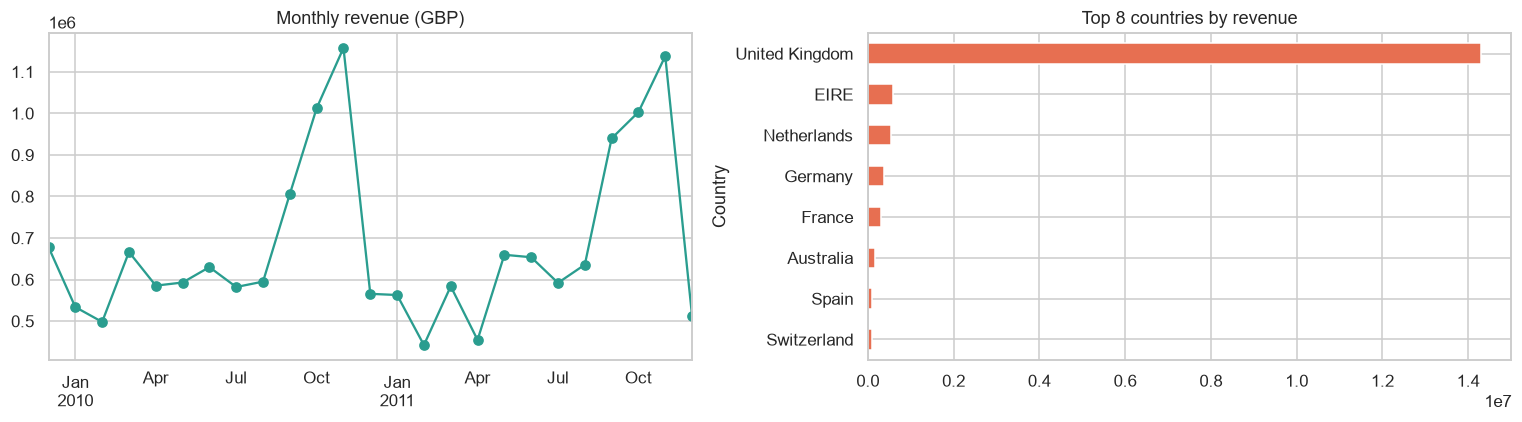

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

monthly = df.groupby(df["InvoiceDate"].dt.to_period("M"))["TotalPrice"].sum()   # works on all pandas versions
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=axes[0], marker="o", color="#2a9d8f")
axes[0].set_title("Monthly revenue (GBP)")
axes[0].set_xlabel("")

top_c = df.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False).head(8)
top_c.sort_values().plot.barh(ax=axes[1], color="#e76f51")
axes[1].set_title("Top 8 countries by revenue")
plt.tight_layout(); save_fig("01_monthly_revenue_and_top_countries"); plt.show()

[saved graph] results\graphs\02_top_products.png


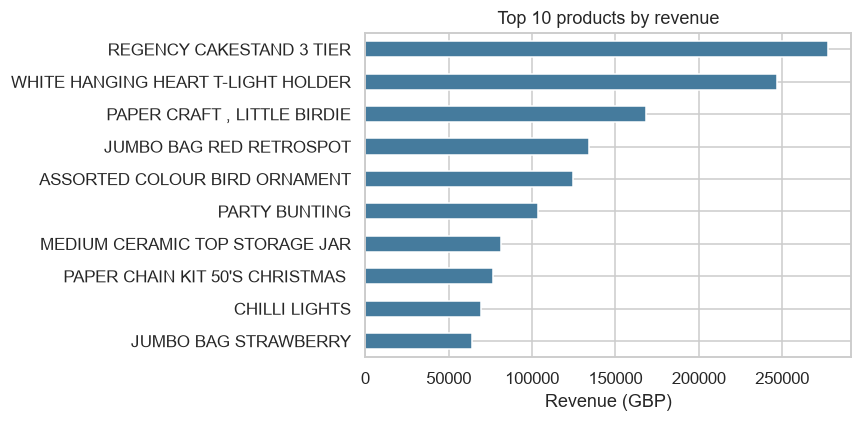

In [55]:
top_products = (df.groupby("Description")["TotalPrice"].sum()
                  .sort_values(ascending=False).head(10))
top_products.sort_values().plot.barh(figsize=(8, 4), color="#457b9d")
plt.title("Top 10 products by revenue"); plt.xlabel("Revenue (GBP)"); plt.ylabel("")
plt.tight_layout(); save_fig("02_top_products"); plt.show()

## 5. RFM feature engineering

Hierarchical clustering works on **customers**, not transactions, so each customer becomes one row:

- **Recency**: days since the last purchase (lower is better)
- **Frequency**: number of distinct invoices (higher is better)
- **Monetary**: total spend (higher is better)

In [56]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (df.groupby("Customer ID")
         .agg(Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
              Frequency=("Invoice", "nunique"),
              Monetary=("TotalPrice", "sum"))
         .reset_index())

print("Customers:", len(rfm))
save_csv(rfm, "02_rfm_table_raw", index=False)
rfm_stats = rfm.describe().round(2)
save_csv(rfm_stats, "03_rfm_summary_statistics")
rfm_stats

Customers: 5853
[saved table] results\tables_csv\02_rfm_table_raw.csv
[saved table] results\tables_csv\03_rfm_summary_statistics.csv


,Customer ID,Recency,Frequency,Monetary
count,5853.00,5853.00,5853.00,5853.00
mean,15319.27,200.25,6.25,2918.48
std,1715.12,208.53,12.76,14335.33
min,12346.00,1.00,1.00,2.95
25%,13837.00,25.00,1.00,340.85
50%,15320.00,95.00,3.00,856.03
75%,16802.00,379.00,7.00,2240.90
max,18287.00,739.00,375.00,580987.04


[saved graph] results\graphs\03_rfm_distributions_raw.png


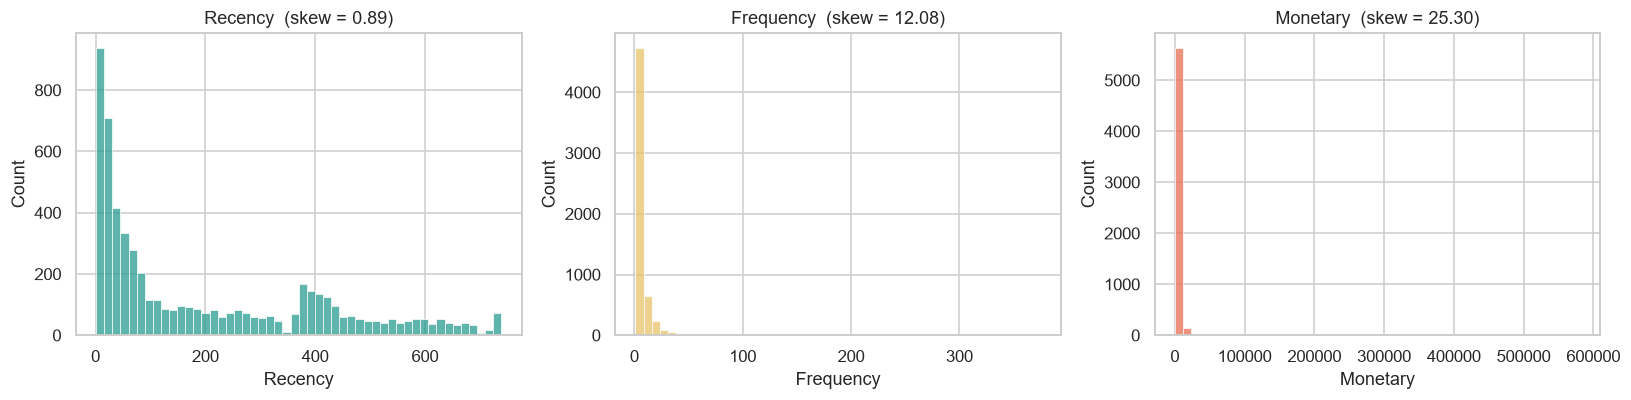

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, color in zip(axes, ["Recency", "Frequency", "Monetary"],
                          ["#2a9d8f", "#e9c46a", "#e76f51"]):
    sns.histplot(rfm[col], bins=50, ax=ax, color=color)
    ax.set_title(f"{col}  (skew = {rfm[col].skew():.2f})")
plt.tight_layout(); save_fig("03_rfm_distributions_raw"); plt.show()

[saved graph] results\graphs\04_rfm_correlation.png


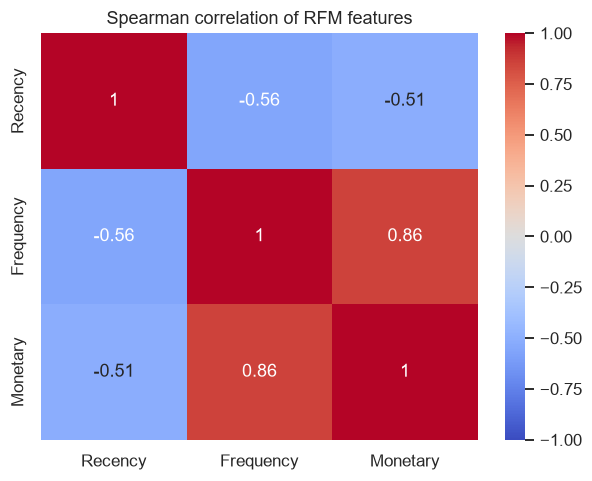

In [58]:
sns.heatmap(rfm[["Recency", "Frequency", "Monetary"]].corr(method="spearman"),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation of RFM features"); save_fig("04_rfm_correlation"); plt.show()

## 6. Outliers, log transform and scaling

- Frequency and Monetary are strongly **right-skewed**, so a **log transform** is applied.
- Extreme outliers (a few huge wholesale customers) can distort Ward linkage, so they are flagged and optionally capped.
- Features are then standardised so that no feature dominates the Euclidean distance.

In [59]:
# Cap extreme values at the 99.5th percentile (winsorising). Set to False to disable.
CAP_OUTLIERS = True
CAP_Q = 0.995

rfm_proc = rfm[["Recency", "Frequency", "Monetary"]].copy()
if CAP_OUTLIERS:
    for c in rfm_proc.columns:
        cap = rfm_proc[c].quantile(CAP_Q)
        n_cap = (rfm_proc[c] > cap).sum()
        rfm_proc[c] = rfm_proc[c].clip(upper=cap)
        print(f"{c:10s} capped {n_cap} customers at {cap:,.1f}")

rfm_log = np.log1p(rfm_proc)

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
print("\nScaled matrix:", X.shape, "| mean ~", X.mean(0).round(3), "| std ~", X.std(0).round(3))

Recency    capped 26 customers at 733.0
Frequency  capped 30 customers at 68.2
Monetary   capped 30 customers at 53,913.9

Scaled matrix: (5853, 3) | mean ~ [-0.  0.  0.] | std ~ [1. 1. 1.]


[saved graph] results\graphs\05_log_transform_before_after.png


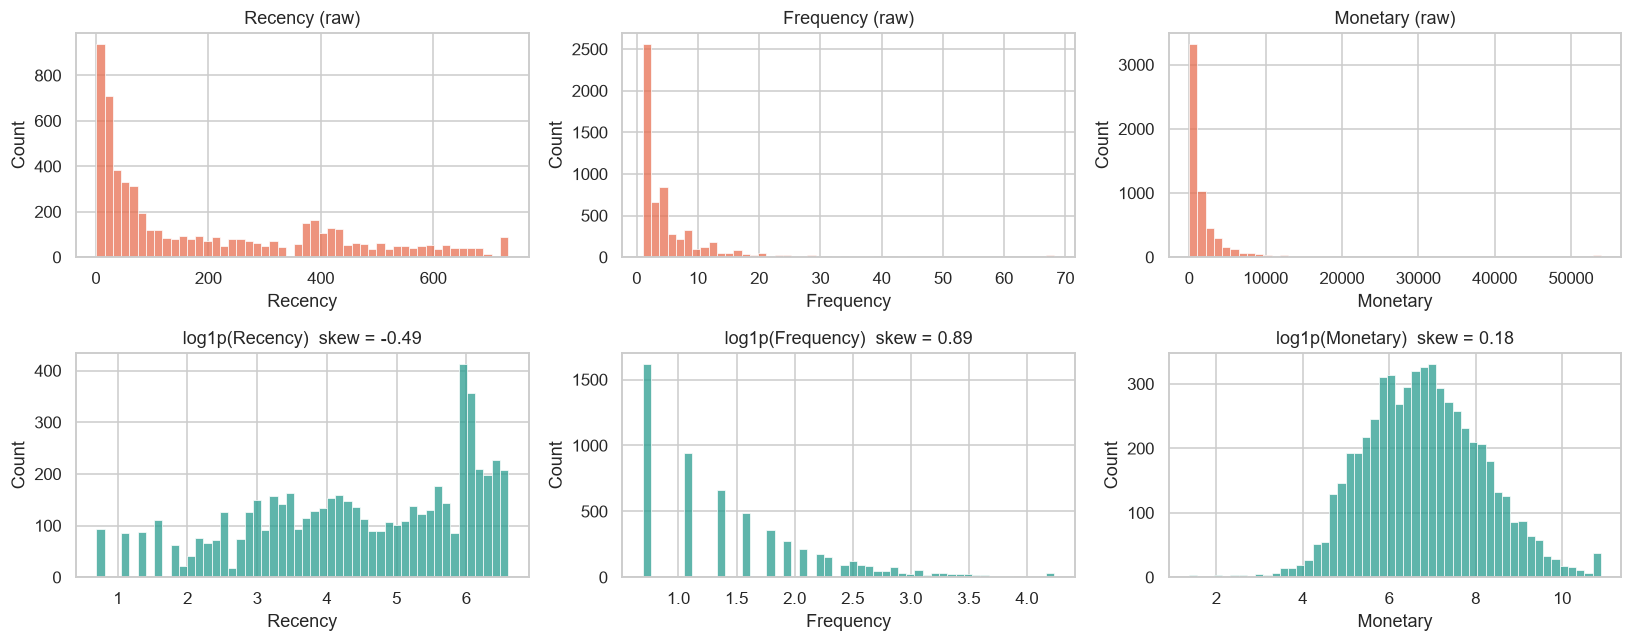

In [60]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for j, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm_proc[col], bins=50, ax=axes[0, j], color="#e76f51")
    axes[0, j].set_title(f"{col} (raw)")
    sns.histplot(rfm_log[col], bins=50, ax=axes[1, j], color="#2a9d8f")
    axes[1, j].set_title(f"log1p({col})  skew = {rfm_log[col].skew():.2f}")
plt.tight_layout(); save_fig("05_log_transform_before_after"); plt.show()

## 7. Hierarchical clustering from scratch

Before using the library, here is the algorithm written by hand so every step is visible.

**Algorithm (agglomerative):**
1. Every point starts as its own cluster.
2. Compute all pairwise distances.
3. Find the two closest clusters and merge them.
4. Update distances to the new cluster using the linkage rule (Lance-Williams update).
5. Repeat until one cluster remains.

The function returns a *linkage matrix* in the same format as SciPy: each row is
`[cluster_i, cluster_j, merge_distance, size_of_new_cluster]`.

In [61]:
def agglomerative_from_scratch(X, method="single", verbose=False):
    """
    Naive O(n^3) agglomerative clustering.
    Supported: 'single', 'complete', 'average', 'ward' (Euclidean distance).
    Returns a SciPy-style linkage matrix Z of shape (n-1, 4).
    """
    X = np.asarray(X, dtype=float)
    n = len(X)
    # Ward's Lance-Williams update works on squared distances
    D = squareform(pdist(X, "euclidean"))
    if method == "ward":
        D = D ** 2
    np.fill_diagonal(D, np.inf)

    sizes = {i: 1 for i in range(n)}      # cluster id -> size
    active = list(range(n))               # ids of live clusters
    # distance dict between live clusters
    dist = {(i, j): D[i, j] for i in range(n) for j in range(i + 1, n)}

    def key(a, b): return (a, b) if a < b else (b, a)

    Z = []
    next_id = n
    for step in range(n - 1):
        # 1. closest pair
        (a, b), d_ab = min(dist.items(), key=lambda kv: kv[1])
        na, nb = sizes[a], sizes[b]

        # 2. record merge
        height = np.sqrt(d_ab) if method == "ward" else d_ab   # D holds squared distances for Ward
        Z.append([a, b, height, na + nb])
        if verbose:
            print(f"step {step+1:>2}: merge {a} + {b}  at distance {height:.4f}  (size {na+nb})")

        # 3. update distances from the new cluster to every other live cluster
        new = next_id; next_id += 1
        for k in active:
            if k in (a, b):
                continue
            d_ak, d_bk = dist[key(a, k)], dist[key(b, k)]
            nk = sizes[k]
            if method == "single":
                d_new = min(d_ak, d_bk)
            elif method == "complete":
                d_new = max(d_ak, d_bk)
            elif method == "average":
                d_new = (na * d_ak + nb * d_bk) / (na + nb)
            elif method == "ward":
                tot = na + nb + nk
                d_new = ((na + nk) * d_ak + (nb + nk) * d_bk - nk * d_ab) / tot
            else:
                raise ValueError("unknown method")
            dist[key(new, k)] = d_new

        # 4. remove old clusters, add the new one
        for k in active:
            dist.pop(key(a, k), None)
            dist.pop(key(b, k), None)
        active = [k for k in active if k not in (a, b)] + [new]
        sizes[new] = na + nb

    return np.array(Z)

### Test on the tiny worked example (A=1, B=2, C=6, D=7, E=15)

In [62]:
toy = np.array([[1], [2], [6], [7], [15]], dtype=float)
Z_toy = agglomerative_from_scratch(toy, "single", verbose=True)
print()
print("Linkage matrix (from scratch):")
print(pd.DataFrame(Z_toy, columns=["cluster_i", "cluster_j", "distance", "size"]))

step  1: merge 0 + 1  at distance 1.0000  (size 2)
step  2: merge 2 + 3  at distance 1.0000  (size 2)
step  3: merge 5 + 6  at distance 4.0000  (size 4)
step  4: merge 4 + 7  at distance 8.0000  (size 5)

Linkage matrix (from scratch):
   cluster_i  cluster_j  distance  size
0        0.0        1.0       1.0   2.0
1        2.0        3.0       1.0   2.0
2        5.0        6.0       4.0   4.0
3        4.0        7.0       8.0   5.0


[saved graph] results\graphs\06_toy_dendrogram_from_scratch.png


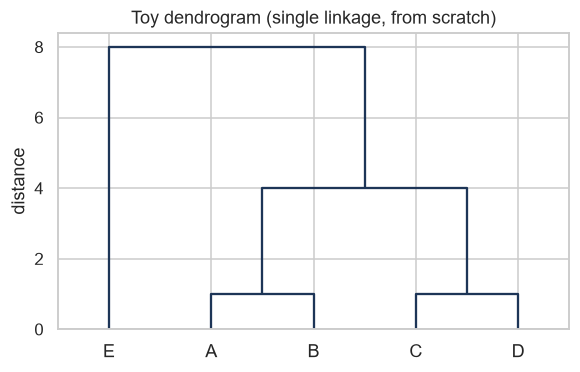

In [63]:
fig, ax = plt.subplots(figsize=(6, 3.5))
dendrogram(Z_toy, labels=list("ABCDE"), ax=ax, color_threshold=0,
           above_threshold_color="#1d3557")
ax.set_title("Toy dendrogram (single linkage, from scratch)"); ax.set_ylabel("distance")
save_fig("06_toy_dendrogram_from_scratch"); plt.show()

### Verify the scratch version against SciPy on real customer data

In [64]:
# use a random sample of customers so the naive O(n^3) code stays fast
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X), size=min(250, len(X)), replace=False)
X_s = X[idx]

rows = []
for m in ["single", "complete", "average", "ward"]:
    Z_mine = agglomerative_from_scratch(X_s, m)
    Z_sp = linkage(X_s, method=m)
    same = np.allclose(np.sort(Z_mine[:, 2]), np.sort(Z_sp[:, 2]), atol=1e-6)
    rows.append((m, same, np.abs(np.sort(Z_mine[:, 2]) - np.sort(Z_sp[:, 2])).max()))
scratch_check = pd.DataFrame(rows, columns=["linkage", "merge heights match SciPy", "max abs difference"])
save_csv(scratch_check, "04_scratch_vs_scipy_check", index=False)
scratch_check

[saved table] results\tables_csv\04_scratch_vs_scipy_check.csv


,linkage,merge heights match SciPy,max abs difference
0,single,True,0.000000e+00
1,complete,True,0.000000e+00
2,average,True,2.220446e-16
3,ward,True,3.552714e-15


## 8. Hierarchical clustering with SciPy

The scratch version is for learning. For all customers, use SciPy (fast, optimised C code).

In [65]:
Z_ward = linkage(X, method="ward", metric="euclidean")
print("Linkage matrix shape:", Z_ward.shape)
pd.DataFrame(Z_ward[-5:], columns=["cluster_i", "cluster_j", "distance", "size"])

Linkage matrix shape: (5852, 4)


,cluster_i,cluster_j,distance,size
0,11693.0,11698.0,39.811909,1496.0
1,11694.0,11696.0,45.495035,2434.0
2,11697.0,11701.0,52.013845,3489.0
3,11699.0,11700.0,55.271230,2364.0
4,11702.0,11703.0,132.704378,5853.0


## 9. Comparing linkage methods

**Cophenetic correlation** measures how faithfully the dendrogram preserves the original pairwise distances
(closer to 1 is better). Silhouette at K=4 gives a quick quality check for each linkage.

In [66]:
orig_dist = pdist(X)
rows = []
linkages = {}
for m in ["single", "complete", "average", "ward"]:
    Zm = linkage(X, method=m)
    linkages[m] = Zm
    c, _ = cophenet(Zm, orig_dist)
    lab = fcluster(Zm, t=4, criterion="maxclust")
    sil = silhouette_score(X, lab) if len(set(lab)) > 1 else np.nan
    sizes = np.bincount(lab)[1:]
    rows.append((m, round(c, 4), round(sil, 4), sizes.tolist()))

cmp_df = pd.DataFrame(rows, columns=["linkage", "cophenetic_corr", "silhouette_K4", "cluster_sizes_K4"])
save_csv(cmp_df, "05_linkage_comparison", index=False)
cmp_df

[saved table] results\tables_csv\05_linkage_comparison.csv


,linkage,cophenetic_corr,silhouette_K4,cluster_sizes_K4
0,single,0.4380,0.1116,"[5850, 1, 1, 1]"
1,complete,0.6286,0.1894,"[172, 658, 3191, 1832]"
2,average,0.6969,0.3576,"[3339, 2413, 10, 91]"
3,ward,0.6084,0.2704,"[1055, 2434, 868, 1496]"


Notes for interpretation:

- **Single** often has a high cophenetic value but gives one giant cluster plus tiny ones (chaining), which is useless for segmentation.
- **Ward** gives balanced, compact clusters, which is why it is used in this notebook.

## 10. Dendrogram

A dendrogram of all customers is unreadable, so the plot is truncated to the last 30 merges.

[saved graph] results\graphs\07_dendrogram_ward.png


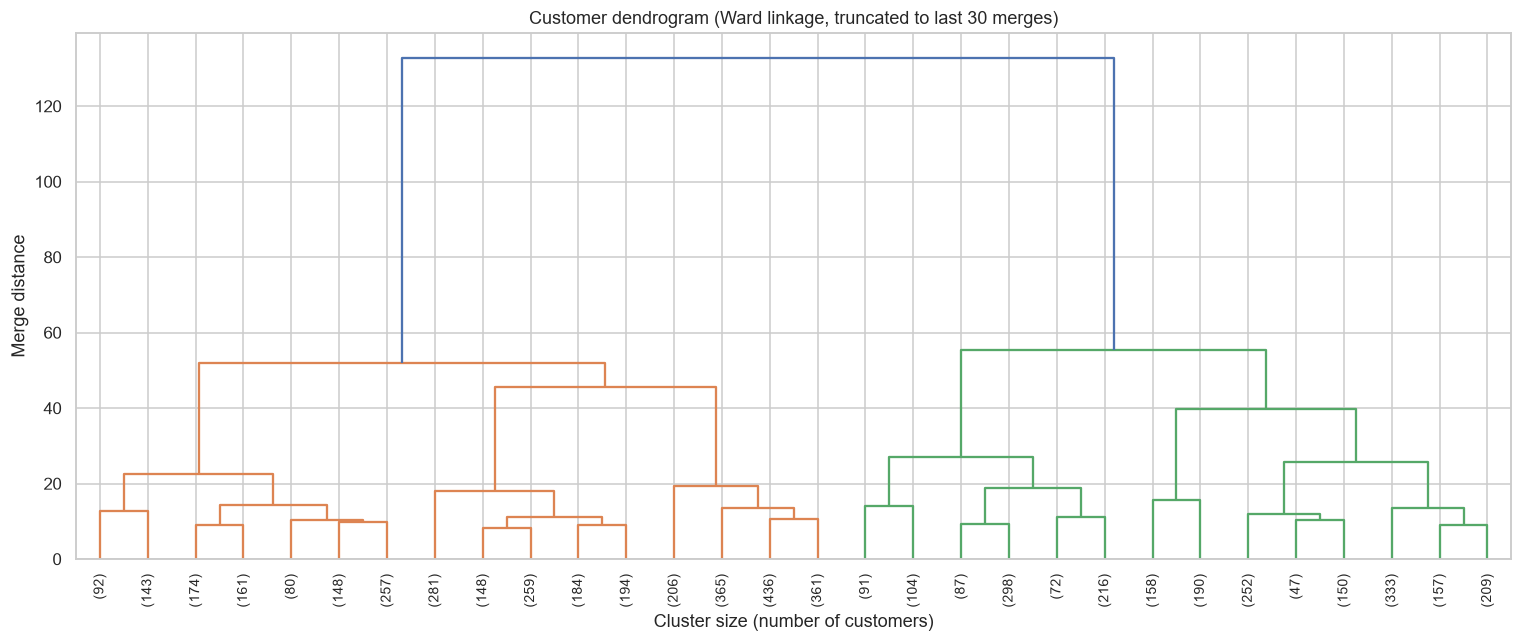

In [67]:
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=9, ax=ax, color_threshold=0.7 * Z_ward[-1, 2])
ax.set_title("Customer dendrogram (Ward linkage, truncated to last 30 merges)")
ax.set_xlabel("Cluster size (number of customers)"); ax.set_ylabel("Merge distance")
plt.tight_layout(); save_fig("07_dendrogram_ward"); plt.show()

[saved graph] results\graphs\08_merge_height_gaps.png


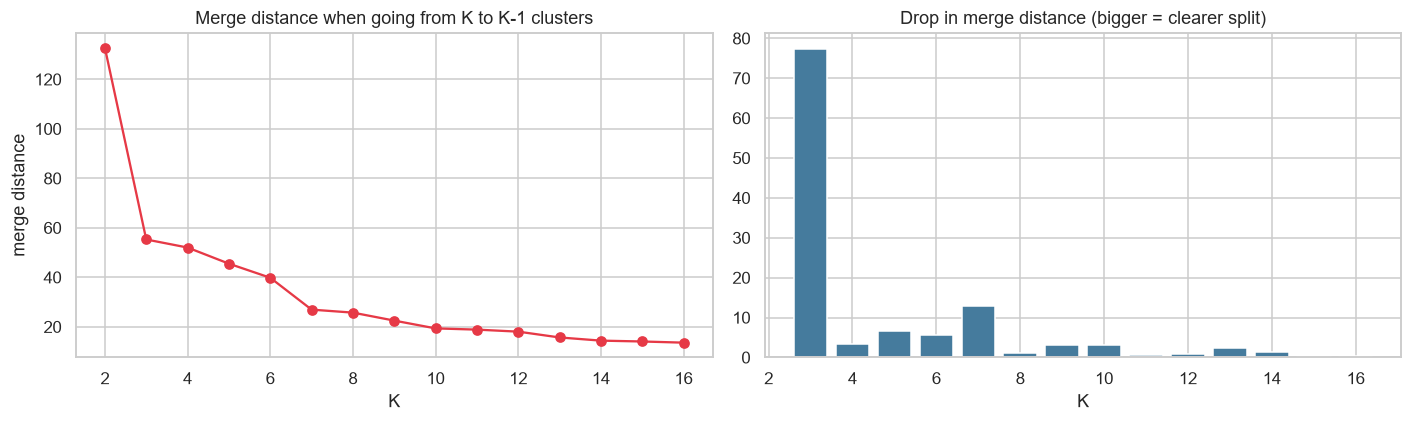

In [68]:
# The last merge heights: a large jump suggests a natural number of clusters
heights = Z_ward[-15:, 2][::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(2, 2 + len(heights)), heights, marker="o", color="#e63946")
ax[0].set_title("Merge distance when going from K to K-1 clusters")
ax[0].set_xlabel("K"); ax[0].set_ylabel("merge distance")

jumps = -np.diff(heights)
ax[1].bar(range(3, 2 + len(heights)), jumps, color="#457b9d")
ax[1].set_title("Drop in merge distance (bigger = clearer split)")
ax[1].set_xlabel("K"); plt.tight_layout(); save_fig("08_merge_height_gaps"); plt.show()

## 11. Choosing the number of clusters

Three internal metrics are computed for each K:

| Metric | Better |
|---|---|
| Silhouette | higher |
| Calinski-Harabasz | higher |
| Davies-Bouldin | lower |

In [69]:
metrics = []
for k in K_RANGE:
    labels_k = fcluster(Z_ward, t=k, criterion="maxclust")
    metrics.append({"K": k,
                    "silhouette": silhouette_score(X, labels_k),
                    "calinski_harabasz": calinski_harabasz_score(X, labels_k),
                    "davies_bouldin": davies_bouldin_score(X, labels_k)})
metrics_df = pd.DataFrame(metrics).set_index("K")
save_csv(metrics_df.round(4), "06_k_metrics")
metrics_df.round(4)

[saved table] results\tables_csv\06_k_metrics.csv


,silhouette,calinski_harabasz,davies_bouldin
K,,,
2,0.4206,5885.3903,0.8999
3,0.3124,4182.3628,1.1589
4,0.2704,3878.8200,1.2050
5,0.2679,3843.4034,1.0850
6,0.2835,3905.3521,0.9777
7,0.2748,3670.0479,1.0215
8,0.2698,3537.7117,1.0460
9,0.2636,3407.1168,1.0821
10,0.2371,3264.1803,1.0598


[saved graph] results\graphs\09_k_selection_metrics.png


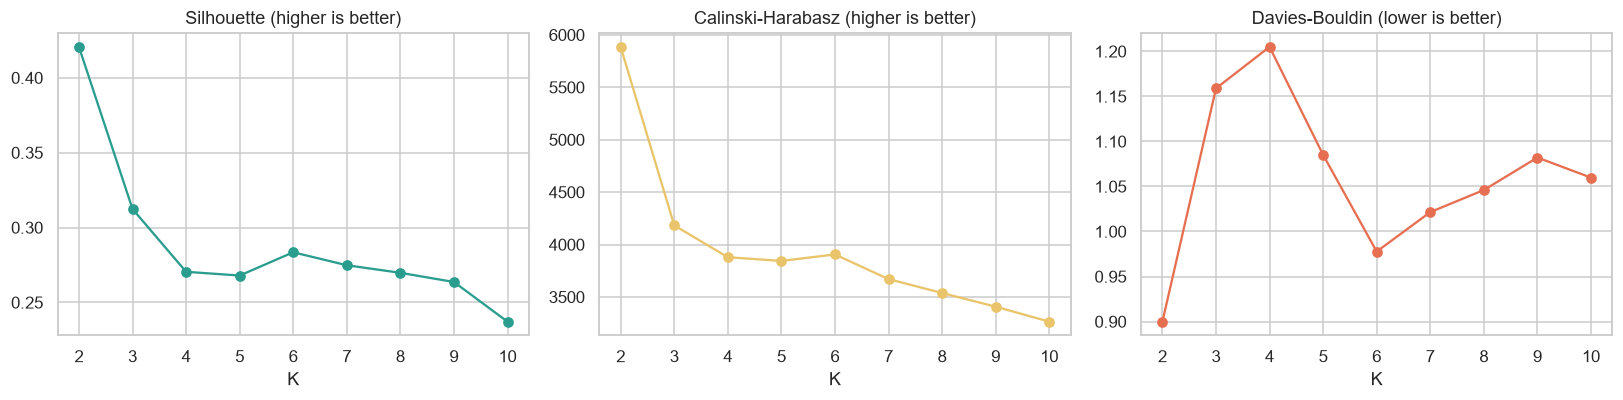

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
metrics_df["silhouette"].plot(ax=axes[0], marker="o", color="#2a9d8f");        axes[0].set_title("Silhouette (higher is better)")
metrics_df["calinski_harabasz"].plot(ax=axes[1], marker="o", color="#e9c46a"); axes[1].set_title("Calinski-Harabasz (higher is better)")
metrics_df["davies_bouldin"].plot(ax=axes[2], marker="o", color="#e76f51");    axes[2].set_title("Davies-Bouldin (lower is better)")
plt.tight_layout(); save_fig("09_k_selection_metrics"); plt.show()

In [71]:
best_k_sil = int(metrics_df["silhouette"].idxmax())
K = FORCE_K if FORCE_K else best_k_sil
print(f"Best K by silhouette : {best_k_sil}")
print(f"K used in this run   : {K}")
print()
print("Tip: if K=2 wins statistically but the business needs more detail, set FORCE_K = 4 above")
print("     and re-run from here. Also check the dendrogram gap and whether the segments are actionable.")

Best K by silhouette : 2
K used in this run   : 3

Tip: if K=2 wins statistically but the business needs more detail, set FORCE_K = 4 above
     and re-run from here. Also check the dendrogram gap and whether the segments are actionable.


### 11b. Side-by-side comparison of candidate K values

Metrics alone are not enough, so this adds **stability** (re-clustering 80% subsamples, ARI close to 1 = stable)
and the **size of the smallest cluster** for K = 2 to 6. Below that, the **median** RFM profile of each candidate K is shown
so you can judge which segmentation is actually useful to the business.

Rule of thumb for stability ARI: above 0.8 high, 0.6 to 0.8 moderate, below 0.6 weak.

In [72]:
from IPython.display import display

def stability_ari(k, n_rep=10, frac=0.8, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    full = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    scores = []
    for _ in range(n_rep):
        sub = rng.choice(len(X), size=int(frac * len(X)), replace=False)
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[sub])
        scores.append(adjusted_rand_score(full[sub], lab))
    return np.mean(scores), np.min(scores), full

rows = []
for k in [2, 3, 4, 5, 6]:
    m_ari, min_ari, lab_k = stability_ari(k)
    rows.append({"K": k,
                 "silhouette": silhouette_score(X, lab_k),
                 "davies_bouldin": davies_bouldin_score(X, lab_k),
                 "calinski_harabasz": calinski_harabasz_score(X, lab_k),
                 "stability_ARI_mean": m_ari,
                 "stability_ARI_min": min_ari,
                 "smallest_cluster_%": 100 * np.bincount(lab_k).min() / len(lab_k)})
k_compare = pd.DataFrame(rows).set_index("K").round(3)
save_csv(k_compare, "07_k_comparison_with_stability")
k_compare

[saved table] results\tables_csv\07_k_comparison_with_stability.csv


,silhouette,davies_bouldin,calinski_harabasz,stability_ARI_mean,stability_ARI_min,smallest_cluster_%
K,,,,,,
2,0.421,0.900,5885.390,0.529,0.264,40.390
3,0.312,1.159,4182.363,0.412,0.231,14.830
4,0.270,1.205,3878.820,0.481,0.398,14.830
5,0.268,1.085,3843.403,0.498,0.373,14.830
6,0.283,0.978,3905.352,0.492,0.405,5.946


[saved graph] results\graphs\10_k_comparison_stability.png


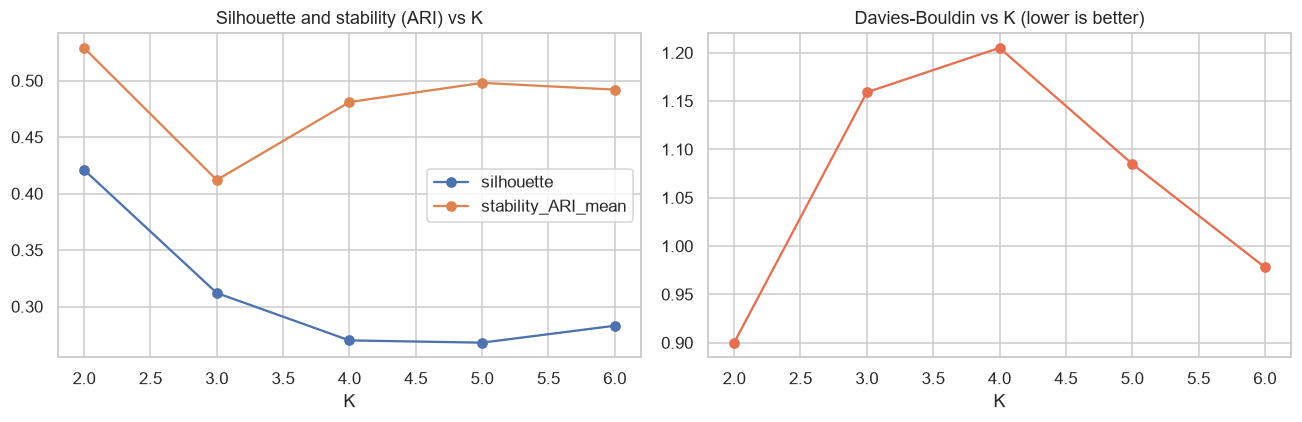

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
k_compare[["silhouette", "stability_ARI_mean"]].plot(marker="o", ax=ax[0])
ax[0].set_title("Silhouette and stability (ARI) vs K")
k_compare["davies_bouldin"].plot(marker="o", ax=ax[1], color="#e76f51")
ax[1].set_title("Davies-Bouldin vs K (lower is better)")
plt.tight_layout(); save_fig("10_k_comparison_stability"); plt.show()

In [74]:
# Median RFM profile for each candidate K (medians are not distorted by a few huge customers)
for k in [2, 3, 4, 6]:
    lab_k = fcluster(Z_ward, t=k, criterion="maxclust")
    tmp = rfm[["Recency", "Frequency", "Monetary"]].copy()
    tmp["Cluster"] = lab_k
    prof_k = (tmp.groupby("Cluster")
                 .agg(Customers=("Recency", "size"),
                      Recency_med=("Recency", "median"),
                      Frequency_med=("Frequency", "median"),
                      Monetary_med=("Monetary", "median"))
                 .round(1))
    prof_k["Customers_%"] = (100 * prof_k["Customers"] / len(tmp)).round(1)
    print(f"\n=== K = {k} (median RFM per cluster) ===")
    save_csv(prof_k, f"08_profile_median_K{k}")
    display(prof_k)


=== K = 2 (median RFM per cluster) ===
[saved table] results\tables_csv\08_profile_median_K2.csv


,Customers,Recency_med,Frequency_med,Monetary_med,Customers_%
Cluster,,,,,
1,3489,284.0,2.0,409.6,59.6
2,2364,26.0,8.0,2840.7,40.4



=== K = 3 (median RFM per cluster) ===
[saved table] results\tables_csv\08_profile_median_K3.csv


,Customers,Recency_med,Frequency_med,Monetary_med,Customers_%
Cluster,,,,,
1,3489,284.0,2.0,409.6,59.6
2,868,15.0,16.0,6027.0,14.8
3,1496,49.0,6.0,1897.8,25.6



=== K = 4 (median RFM per cluster) ===
[saved table] results\tables_csv\08_profile_median_K4.csv


,Customers,Recency_med,Frequency_med,Monetary_med,Customers_%
Cluster,,,,,
1,1055,44.0,2.0,409.8,18.0
2,2434,396.0,2.0,409.3,41.6
3,868,15.0,16.0,6027.0,14.8
4,1496,49.0,6.0,1897.8,25.6



=== K = 6 (median RFM per cluster) ===
[saved table] results\tables_csv\08_profile_median_K6.csv


,Customers,Recency_med,Frequency_med,Monetary_med,Customers_%
Cluster,,,,,
1,1055,44.0,2.0,409.8,18.0
2,1066,366.0,3.0,908.7,18.2
3,1368,425.0,1.0,239.3,23.4
4,868,15.0,16.0,6027.0,14.8
5,348,4.0,4.5,1286.5,5.9
6,1148,63.0,6.0,2103.0,19.6


**How to decide:** prefer the K whose segments (a) have clearly different RFM profiles, (b) are not tiny, (c) have
reasonable stability, and (d) you can describe and act on in one sentence each. K=2 is the most separated statistically,
K=3 and K=6 are the next natural levels, and K=4 is usually the weakest on Davies-Bouldin.

## 12. Final model

In [75]:
final = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")
labels = final.fit_predict(X)

rfm["Cluster"] = labels
print("Silhouette:", round(silhouette_score(X, labels), 4))
print("Davies-Bouldin:", round(davies_bouldin_score(X, labels), 4))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X, labels), 1))
print()
print(rfm["Cluster"].value_counts().sort_index())

Silhouette: 0.3124
Davies-Bouldin: 1.1589
Calinski-Harabasz: 4182.4

Cluster
0    3489
1    1496
2     868
Name: count, dtype: int64


In [76]:
# Cross-check: scipy cut and sklearn give the same partition
lab_sp = fcluster(Z_ward, t=K, criterion="maxclust") - 1
print("Agreement between sklearn and scipy (ARI):", round(adjusted_rand_score(labels, lab_sp), 4))

Agreement between sklearn and scipy (ARI): 1.0


## 13. Cluster profiling and segment naming

Profiling uses the **original** (not log) values so that the numbers are meaningful to business users.

In [77]:
profile = (rfm.groupby("Cluster")
             .agg(Customers=("Customer ID", "count"),
                  Recency=("Recency", "mean"),
                  Frequency=("Frequency", "mean"),
                  Monetary=("Monetary", "mean"),
                  Recency_med=("Recency", "median"),
                  Frequency_med=("Frequency", "median"),
                  Monetary_med=("Monetary", "median"),
                  Total_Revenue=("Monetary", "sum"))
             .round(1))
profile["Customers_%"] = (100 * profile["Customers"] / profile["Customers"].sum()).round(1)
profile["Revenue_%"] = (100 * profile["Total_Revenue"] / profile["Total_Revenue"].sum()).round(1)
profile

,Customers,Recency,Frequency,Monetary,Recency_med,Frequency_med,Monetary_med,Total_Revenue,Customers_%,Revenue_%
Cluster,,,,,,,,,,
0,3489,296.6,2.1,570.0,284.0,2.0,409.6,1988675.8,59.6,11.6
1,1496,78.1,6.3,2569.6,49.0,6.0,1897.8,3844061.0,25.6,22.5
2,868,23.6,22.9,12959.8,15.0,16.0,6027.0,11249123.0,14.8,65.9


In [78]:
# Automatic naming: rank clusters by a simple RFM quality score
# medians are used for ranking because means are inflated by a few very large customers
rank_r = profile["Recency_med"].rank(ascending=False)    # low recency = good = high rank
rank_f = profile["Frequency_med"].rank()
rank_m = profile["Monetary_med"].rank()
profile["score"] = rank_r + rank_f + rank_m
order = profile["score"].sort_values(ascending=False).index.tolist()

names_by_k = {
    2: ["Valuable", "Low value"],
    3: ["Champions", "Potential", "Lost / Low value"],
    4: ["Champions", "Loyal customers", "At risk", "Lost / Dormant"],
}
# NOTE: names are assigned by rank only. Always check them against the profile table and rename if needed.
# For K > 4 automatic business names would often be misleading, so neutral tier names are used.
names = names_by_k.get(K, [f"Tier {i+1}" + (" (best)" if i == 0 else " (lowest)" if i == K - 1 else "") for i in range(K)])
print("Segment names (assigned by rank, verify against the profile table and rename if needed):")
print(names)
segment_name = {cl: nm for cl, nm in zip(order, names)}

rfm["Segment"] = rfm["Cluster"].map(segment_name)
profile["Segment"] = profile.index.map(segment_name)
profile_out = profile.sort_values("score", ascending=False).drop(columns="score")
save_csv(profile_out, f"09_segment_profile_K{K}")
profile_out

Segment names (assigned by rank, verify against the profile table and rename if needed):
['Champions', 'Potential', 'Lost / Low value']
[saved table] results\tables_csv\09_segment_profile_K3.csv


,Customers,Recency,Frequency,Monetary,Recency_med,Frequency_med,Monetary_med,Total_Revenue,Customers_%,Revenue_%,Segment
Cluster,,,,,,,,,,,
2,868,23.6,22.9,12959.8,15.0,16.0,6027.0,11249123.0,14.8,65.9,Champions
1,1496,78.1,6.3,2569.6,49.0,6.0,1897.8,3844061.0,25.6,22.5,Potential
0,3489,296.6,2.1,570.0,284.0,2.0,409.6,1988675.8,59.6,11.6,Lost / Low value


[saved graph] results\graphs\11_segment_customers_vs_revenue.png


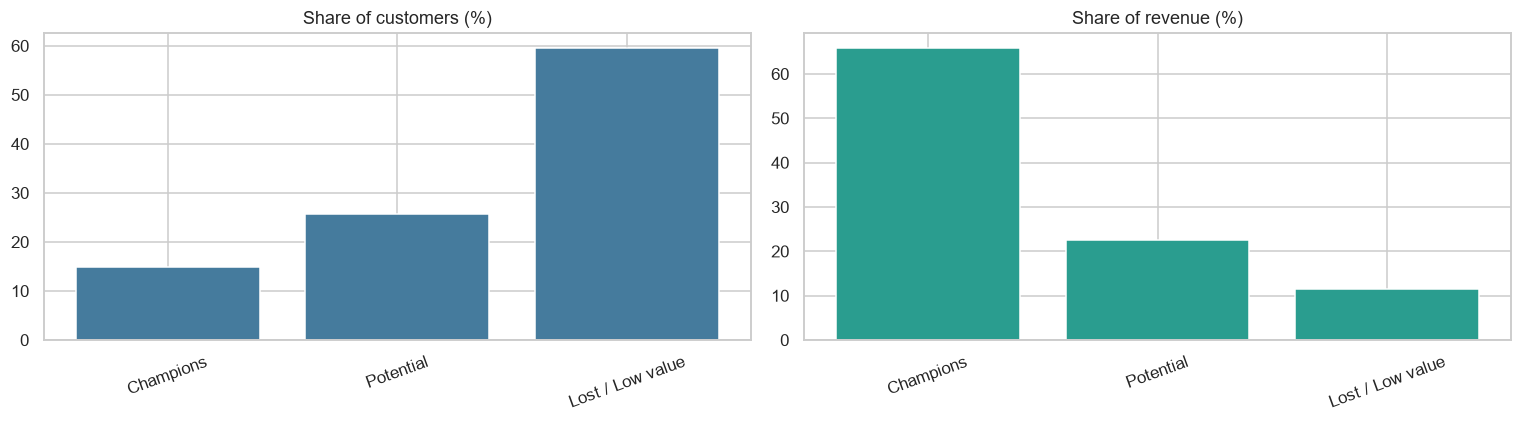

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
prof_plot = profile.sort_values("score", ascending=False)
axes[0].bar(prof_plot["Segment"], prof_plot["Customers_%"], color="#457b9d")
axes[0].set_title("Share of customers (%)"); axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(prof_plot["Segment"], prof_plot["Revenue_%"], color="#2a9d8f")
axes[1].set_title("Share of revenue (%)"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); save_fig("11_segment_customers_vs_revenue"); plt.show()

## 14. Visualization

Explained variance: [0.763 0.188]
[saved graph] results\graphs\12_pca_segments.png


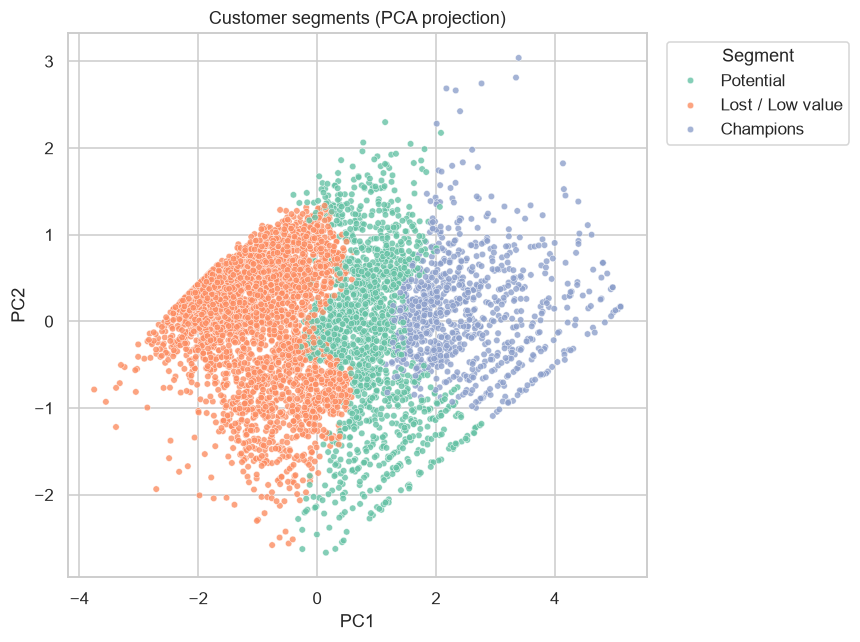

In [80]:
# 14.1 PCA 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
print("Explained variance:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=rfm["Segment"], palette="Set2", s=18, alpha=0.8)
plt.title("Customer segments (PCA projection)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); save_fig("12_pca_segments"); plt.show()

[saved graph] results\graphs\13_segments_3d_rfm.png


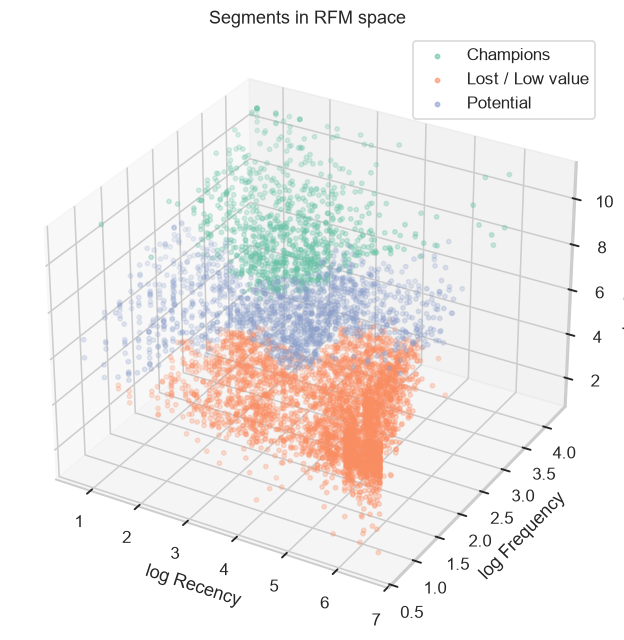

In [81]:
# 14.2 3D scatter in log-RFM space
from mpl_toolkits.mplot3d import Axes3D  # noqa
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
palette = sns.color_palette("Set2", rfm["Segment"].nunique())
for color, (seg, g) in zip(palette, rfm.groupby("Segment")):
    ix = g.index
    ax.scatter(rfm_log.loc[ix, "Recency"], rfm_log.loc[ix, "Frequency"], rfm_log.loc[ix, "Monetary"],
               s=8, alpha=0.6, label=seg, color=color)
ax.set_xlabel("log Recency"); ax.set_ylabel("log Frequency"); ax.set_zlabel("log Monetary")
ax.set_title("Segments in RFM space"); ax.legend()
save_fig("13_segments_3d_rfm"); plt.show()

[saved graph] results\graphs\14_boxplots_by_segment.png


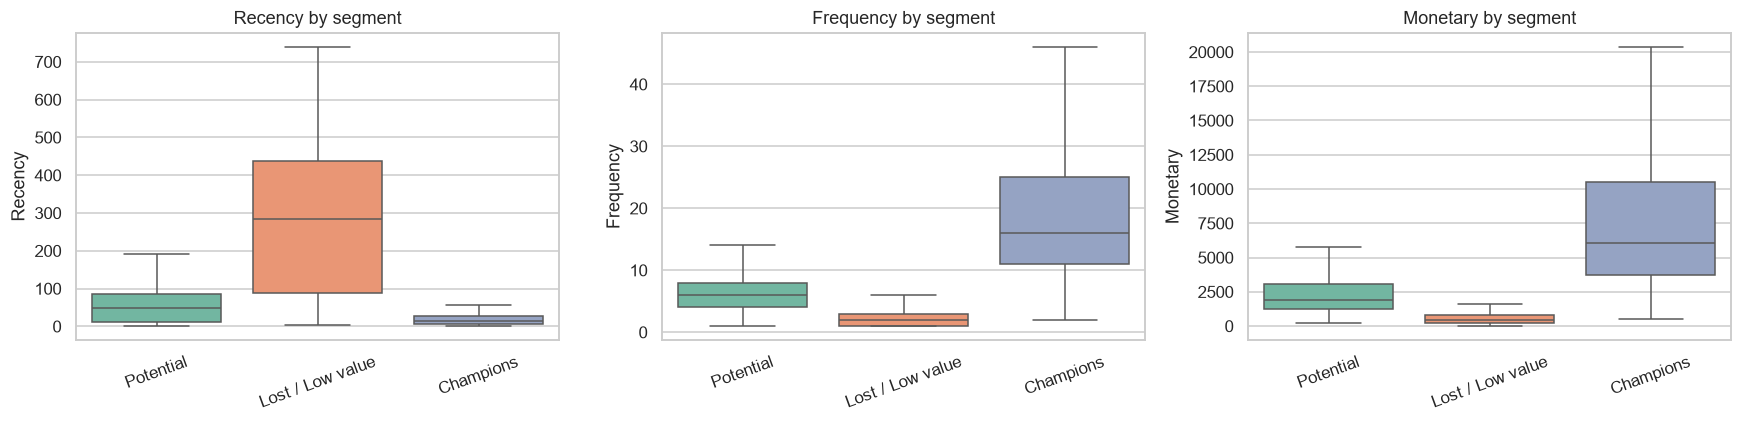

In [82]:
# 14.3 Boxplots per segment
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=rfm, x="Segment", y=col, ax=ax, palette="Set2", showfliers=False)
    ax.set_title(f"{col} by segment"); ax.tick_params(axis="x", rotation=20); ax.set_xlabel("")
plt.tight_layout(); save_fig("14_boxplots_by_segment"); plt.show()

[saved graph] results\graphs\15_heatmap_segment_means.png


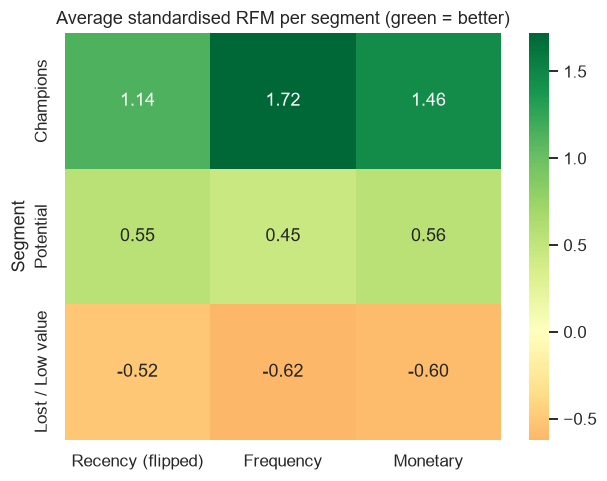

In [83]:
# 14.4 Heatmap of standardised cluster means
z = pd.DataFrame(X, columns=["Recency", "Frequency", "Monetary"])
z["Recency"] = -z["Recency"]                 # flip so that HIGHER = BETTER for all three columns
z["Segment"] = rfm["Segment"].values
hm = z.groupby("Segment").mean().rename(columns={"Recency": "Recency (flipped)"})
hm = hm.loc[profile.sort_values("score", ascending=False)["Segment"]]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Average standardised RFM per segment (green = better)")
save_fig("15_heatmap_segment_means"); plt.show()

[saved graph] results\graphs\16_clustermap_sample.png


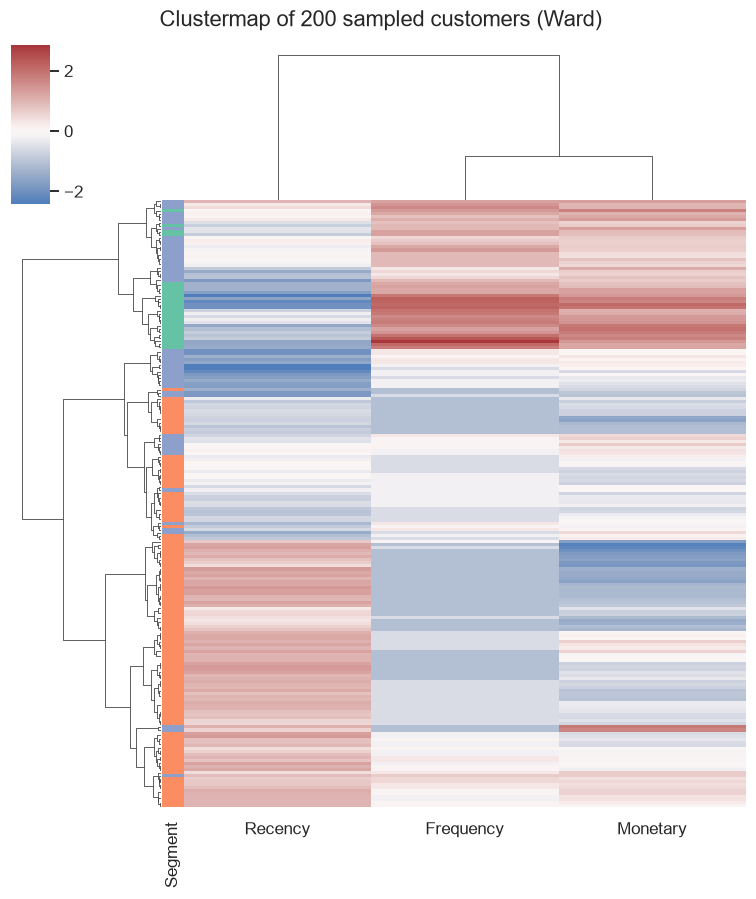

In [84]:
# 14.5 Clustermap (hierarchical clustering applied to rows AND columns) on a sample
samp = rfm.sample(n=min(200, len(rfm)), random_state=RANDOM_STATE)
Xs = pd.DataFrame(X, columns=["Recency", "Frequency", "Monetary"]).loc[samp.index]
seg_colors = dict(zip(sorted(rfm["Segment"].unique()), sns.color_palette("Set2", rfm["Segment"].nunique())))
row_colors = samp["Segment"].map(seg_colors)
g = sns.clustermap(Xs, method="ward", cmap="vlag", row_colors=row_colors,
                   figsize=(7, 8), yticklabels=False, center=0)
g.fig.suptitle("Clustermap of 200 sampled customers (Ward)", y=1.02)
save_fig("16_clustermap_sample", g.fig); plt.show()

## 15. Validation

Two checks that the clusters are not a fluke:

1. **Stability**: re-cluster random 80% subsamples and compare to the full-data labels (ARI close to 1 = stable).
2. **Comparison with K-Means** on the same data (if both methods find similar groups, the structure is real).

In [85]:
# 15.1 Stability via subsampling
rng = np.random.RandomState(RANDOM_STATE)
aris = []
for i in range(20):
    sub = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    lab_sub = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X[sub])
    aris.append(adjusted_rand_score(labels[sub], lab_sub))
save_csv(pd.DataFrame({"subsample": range(1, len(aris) + 1), "ARI": aris}), "10_stability_ari_subsamples", index=False)
print(f"Stability (ARI over 20 subsamples): mean = {np.mean(aris):.3f}, min = {np.min(aris):.3f}")
level = "high" if np.mean(aris) > 0.8 else "moderate" if np.mean(aris) > 0.6 else "weak"
print(f"Interpretation: {level} stability (>0.8 high, 0.6-0.8 moderate, <0.6 weak)")

[saved table] results\tables_csv\10_stability_ari_subsamples.csv
Stability (ARI over 20 subsamples): mean = 0.413, min = 0.231
Interpretation: weak stability (>0.8 high, 0.6-0.8 moderate, <0.6 weak)


In [86]:
# 15.2 Comparison with K-Means
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
print("K-Means silhouette     :", round(silhouette_score(X, km.labels_), 4))
print("Hierarchical silhouette:", round(silhouette_score(X, labels), 4))
print("Agreement (ARI)        :", round(adjusted_rand_score(labels, km.labels_), 4))
print()
ct = pd.crosstab(rfm["Segment"], km.labels_, rownames=["Hierarchical"], colnames=["K-Means"])
print(ct)
save_csv(ct, "11_kmeans_vs_hierarchical_crosstab")

K-Means silhouette     : 0.3485
Hierarchical silhouette: 0.3124
Agreement (ARI)        : 0.4429

K-Means              0     1    2
Hierarchical                     
Champions            6     0  862
Lost / Low value  1101  2388    0
Potential         1143     0  353
[saved table] results\tables_csv\11_kmeans_vs_hierarchical_crosstab.csv


## 16. Business recommendations and export

In [87]:
actions = {
    "Champions": "VIP rewards, early access to new products, referral program.",
    "Valuable": "Protect with loyalty perks and personal service.",
    "Loyal customers": "Upsell and cross-sell, loyalty points, product bundles.",
    "Potential loyalists": "Encourage a second and third purchase with targeted offers.",
    "Potential": "Encourage repeat purchases with targeted offers.",
    "At risk": "Win-back emails, personalised discounts, reminder campaigns.",
    "Lost / Dormant": "Low-cost reactivation survey or last-chance offer, otherwise deprioritise.",
    "Lost / Low value": "Low-cost reactivation or deprioritise.",
    "Low value": "Low-cost automated marketing only.",
}
summary = profile.sort_values("score", ascending=False)[
    ["Segment", "Customers", "Customers_%", "Recency_med", "Frequency_med", "Monetary_med", "Monetary", "Revenue_%"]].copy()
summary = summary.rename(columns={"Monetary": "Monetary_mean"})
summary["Recommended action"] = summary["Segment"].map(actions).fillna("Review manually.")
summary = summary.reset_index(drop=True)
save_csv(summary, "12_segment_summary_and_actions", index=False)
summary

[saved table] results\tables_csv\12_segment_summary_and_actions.csv


,Segment,Customers,Customers_%,Recency_med,Frequency_med,Monetary_med,Monetary_mean,Revenue_%,Recommended action
0,Champions,868,14.8,15.0,16.0,6027.0,12959.8,65.9,"VIP rewards, early access to new products, ref..."
1,Potential,1496,25.6,49.0,6.0,1897.8,2569.6,22.5,Encourage repeat purchases with targeted offers.
2,Lost / Low value,3489,59.6,284.0,2.0,409.6,570.0,11.6,Low-cost reactivation or deprioritise.


In [88]:
rfm.to_csv(OUTPUT_PATH, index=False)
print(f"[saved table] {OUTPUT_PATH}  ({len(rfm)} customers with their segments)")
rfm.head()

[saved table] results\tables_csv\00_customer_segments_final.csv  (5853 customers with their segments)


,Customer ID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,3,77352.96,1,Potential
1,12347,2,8,4921.53,1,Potential
2,12348,75,5,1658.40,1,Potential
3,12349,19,3,3678.69,1,Potential
4,12350,310,1,294.40,0,Lost / Low value


In [89]:
# Auto-generated summary of this run (copy into your report). Also saved to results/run_summary.txt
lines = []
lines.append("=" * 70)
lines.append(f"FINAL SUMMARY: Ward hierarchical clustering, K = {K}")
lines.append("=" * 70)
lines.append(f"Customers segmented : {len(rfm):,}")
lines.append(f"Silhouette          : {silhouette_score(X, labels):.3f}")
lines.append(f"Davies-Bouldin      : {davies_bouldin_score(X, labels):.3f}")
lines.append(f"Stability (ARI)     : {np.mean(aris):.3f} ({level})")
lines.append(f"Agreement with K-Means (ARI): {adjusted_rand_score(labels, km.labels_):.3f}")
lines.append("")
for _, r in profile.sort_values("score", ascending=False).iterrows():
    lines.append(f"- {r['Segment']}: {int(r['Customers']):,} customers ({r['Customers_%']}%), "
                 f"{r['Revenue_%']}% of revenue | median recency {r['Recency_med']:.0f} days, "
                 f"frequency {r['Frequency_med']:.0f}, spend {r['Monetary_med']:,.0f}")
report_text = "\n".join(lines)
print(report_text)
with open(os.path.join(RESULTS_DIR, "run_summary.txt"), "w", encoding="utf-8") as fh:
    fh.write(report_text)

FINAL SUMMARY: Ward hierarchical clustering, K = 3
Customers segmented : 5,853
Silhouette          : 0.312
Davies-Bouldin      : 1.159
Stability (ARI)     : 0.413 (weak)
Agreement with K-Means (ARI): 0.443

- Champions: 868 customers (14.8%), 65.9% of revenue | median recency 15 days, frequency 16, spend 6,027
- Potential: 1,496 customers (25.6%), 22.5% of revenue | median recency 49 days, frequency 6, spend 1,898
- Lost / Low value: 3,489 customers (59.6%), 11.6% of revenue | median recency 284 days, frequency 2, spend 410


### Everything this run saved

In [90]:
for folder, _, files in sorted(os.walk(RESULTS_DIR)):
    depth = folder.count(os.sep)
    print("    " * depth + os.path.basename(folder) + "/")
    for fn in sorted(files):
        print("    " * (depth + 1) + fn)

results/
    run_summary.txt
    graphs/
        01_monthly_revenue_and_top_countries.png
        02_top_products.png
        03_rfm_distributions_raw.png
        04_rfm_correlation.png
        05_log_transform_before_after.png
        06_toy_dendrogram_from_scratch.png
        07_dendrogram_ward.png
        08_merge_height_gaps.png
        09_k_selection_metrics.png
        10_k_comparison_stability.png
        11_segment_customers_vs_revenue.png
        12_pca_segments.png
        13_segments_3d_rfm.png
        14_boxplots_by_segment.png
        15_heatmap_segment_means.png
        16_clustermap_sample.png
    tables_csv/
        00_customer_segments_final.csv
        01_cleaning_log.csv
        02_rfm_table_raw.csv
        03_rfm_summary_statistics.csv
        04_scratch_vs_scipy_check.csv
        05_linkage_comparison.csv
        06_k_metrics.csv
        07_k_comparison_with_stability.csv
        08_profile_median_K2.csv
        08_profile_median_K3.csv
        08_profile_median_K4

## Summary

- Cleaned about 1.07M transactions down to purchases by identified customers.
- Built RFM features, handled skew with log transform and scaled them.
- Implemented agglomerative clustering from scratch and verified it against SciPy.
- Compared linkages (cophenetic correlation), chose Ward, read the dendrogram and picked K using three metrics.
- Profiled the segments, named them, validated stability and compared with K-Means.

**Limitations:** RFM only captures purchase behaviour; adding product mix, country or basket size could refine the segments. Hierarchical clustering does not scale beyond roughly 20,000 customers (use K-Means or BIRCH for larger data).